ПРОЦЕДУРЫ ВКЛЮЧЕНИЯ, ИСКЛЮЧЕНИЯ ПЕРЕМЕННЫХ ИЗ РЕГРЕССИИ.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc

In [2]:
df = pd.read_csv('urozhaynost_usl_own_varince.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      19 non-null     float64
 1   X2      19 non-null     float64
 2   X3      19 non-null     float64
 3   X4      19 non-null     float64
 4   X5      19 non-null     float64
 5   Y       19 non-null     float64
dtypes: float64(6)
memory usage: 1.0 KB


In [4]:
df

,X1,X2,X3,X4,X5,Y
0,1.59,0.26,2.05,0.32,0.14,9.7
1,0.34,0.28,0.46,0.59,0.66,8.4
2,4.63,0.40,6.44,0.43,0.59,9.9
3,2.16,0.26,2.16,0.39,0.16,9.6
4,2.16,0.30,2.69,0.32,0.17,8.6
5,0.68,0.29,0.73,0.42,0.36,12.5
6,0.35,0.26,0.42,0.21,0.08,7.6
7,0.52,0.24,0.49,0.20,0.08,6.9
8,3.42,0.31,3.02,1.37,0.73,13.5
9,1.78,0.30,3.19,0.73,0.17,9.7


In [5]:
import seaborn as sns

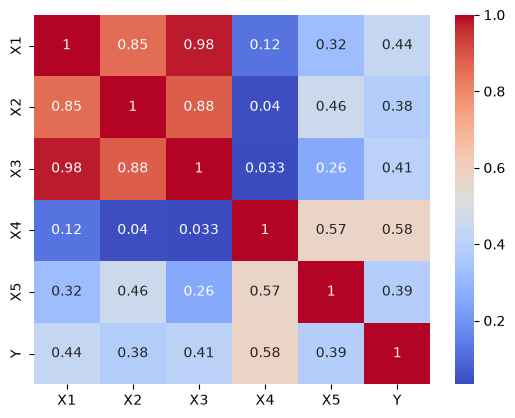

In [6]:
corr_d = df.corr()
sns.heatmap(df.corr(), cmap='coolwarm', annot=True);

In [7]:
def chastnay_corr(rxz, ryz, rxy):
    rxy_z = (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz**2))
    return rxy_z

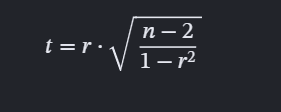
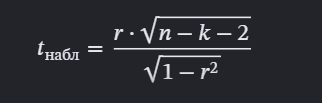

In [8]:
def confidence_parn_coeff(r, n, t_krit):
    try:
        # Считаем t_emp для парной корреляции (df = n - 2)
        t_emp = r * np.sqrt((n - 2) / (1 - r ** 2))
        if abs(t_emp) > abs(t_krit):
            return str(round(r, 2)) + '*'
        else:
            return str(round(r, 2))
    except:
        return "1"

def confidence_chastniy_coeff(r, n, t_krit, k=1):
    try:
        # Для частной корреляции df = n - k - 2
        t_emp = r * np.sqrt((n - k - 2) / (1 - r ** 2))
        if abs(t_emp) > abs(t_krit):
            return str(round(r, 2)) + '*'
        else:
            return str(round(r, 2))
    except:
        return "1"


Матрица парных корреляций ( * - значимый коэффициент)

In [9]:
t_krit_parn = sc.stats.t.ppf(1 - 0.05 / 2, len(df) - 1)
t_krit_chast = sc.stats.t.ppf(1 - 0.05 / 2, len(df) - 3)
n = len(df)
corr_d_parn = corr_d.map(lambda r: confidence_parn_coeff(r, n, t_krit_parn))

In [10]:
corr_d_parn

,X1,X2,X3,X4,X5,Y
X1,1,0.85*,0.98*,0.12,0.32,0.44
X2,0.85*,1,0.88*,0.04,0.46*,0.38
X3,0.98*,0.88*,1,0.03,0.26,0.41
X4,0.12,0.04,0.03,1,0.57*,0.58*
X5,0.32,0.46*,0.26,0.57*,1,0.39
Y,0.44,0.38,0.41,0.58*,0.39,1


In [11]:
for x in corr_d.columns[:-1]:
    max_corr = corr_d[x].drop(x, axis=0)
    x_max_corr = max_corr.drop('Y')
    value, ind = max(x_max_corr), x_max_corr.argmax()
    XX = x_max_corr.index[ind]
    r_chast = chastnay_corr(corr_d[x][XX], corr_d[XX]['Y'], corr_d[x]['Y'])
    znach = confidence_chastniy_coeff(r_chast, n, t_krit_chast, 1)
    print(f'{'--' * 10} {x} {'--' * 10}')
    print(f'Иключаем влияние переменной {XX}')
    print(f'Коэффициент частной корреляции получается: {znach}')

-------------------- X1 --------------------
Иключаем влияние переменной X3
Коэффициент частной корреляции получается: 0.21
-------------------- X2 --------------------
Иключаем влияние переменной X3
Коэффициент частной корреляции получается: 0.06
-------------------- X3 --------------------
Иключаем влияние переменной X1
Коэффициент частной корреляции получается: -0.12
-------------------- X4 --------------------
Иключаем влияние переменной X5
Коэффициент частной корреляции получается: 0.47
-------------------- X5 --------------------
Иключаем влияние переменной X4
Коэффициент частной корреляции получается: 0.09


In [12]:
import statsmodels.formula.api as sm
from scipy import stats

In [15]:
def compare_models(R1, R2, K1, K2, n):
    df1 = K2 - K1          # Степени свободы числителя
    df2 = n - K2 - 1       # Степени свободы знаменателя
    f_krit = stats.f.ppf(1 - 0.05, df1, df2)
    F = ((R2 - R1) / df1) / ((1 - R2) / df2)
    return F > f_krit

spis_regressor = list(df.columns[:-1]) # Приводим к list для удобства drop
curr_regressors = []
start_model = sm.ols('Y ~ 1', df).fit()
n = len(df) # Количество наблюдений

# Сохраняем текущую лучшую модель (изначально это константная модель)
current_best_model = start_model

while True:
    # 1. Проверяем, остались ли еще доступные признаки для добавления
    remaining_features = [f for f in spis_regressor if f not in curr_regressors]
    if not remaining_features:
        print("Все возможные признаки уже добавлены.")
        break
        
    # 2. Ищем признак с максимальной корреляцией среди оставшихся
    idx_for_max_corr = corr_d['Y'].drop(curr_regressors + ['Y']).argmax()
    next_to_add = remaining_features[idx_for_max_corr]
    
    # 3. Формируем новый список регрессоров
    regressors_with_added = curr_regressors + [next_to_add]
    
    # 4. Обучаем новую модель для сравнения
    formula = f"Y ~ {' + '.join(regressors_with_added)}"
    model_for_compare = sm.ols(formula, df).fit()
    
    # 5. Сравниваем модели с помощью функции compare_models
    # K1 и K2 — это количество регрессоров (параметров без константы)
    K1 = len(curr_regressors)
    K2 = len(regressors_with_added)
    
    is_better = compare_models(
        R1=current_best_model.rsquared, 
        R2=model_for_compare.rsquared, 
        K1=K1, 
        K2=K2, 
        n=n
    )
    
    # 6. Условие добавления или остановки цикла
    if is_better:
        curr_regressors.append(next_to_add)
        current_best_model = model_for_compare
        print(f"Добавлен признак: {next_to_add} (R2 улучшился до {model_for_compare.rsquared:.4f})")
    else:
        print(f"Признак {next_to_add} не улучшил модель значимо. Остановка отбора.")
        break

print("\nФинальный набор регрессоров:", curr_regressors)
print(current_best_model.summary())


Добавлен признак: X4 (R2 улучшился до 0.3307)
Признак X1 не улучшил модель значимо. Остановка отбора.

Финальный набор регрессоров: ['X4']
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.331
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     8.401
Date:                Wed, 14 Oct 2026   Prob (F-statistic):             0.0100
Time:                        15:55:39   Log-Likelihood:                -36.044
No. Observations:                  19   AIC:                             76.09
Df Residuals:                      17   BIC:                             77.98
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025     

In [16]:
import pandas as pd
import statsmodels.formula.api as sm
from scipy import stats

def compare_models(R1, R2, K1, K2, n):
    df1 = K2 - K1          # Степени свободы числителя
    df2 = n - K2 - 1       # Степени свободы знаменателя
    f_krit = stats.f.ppf(1 - 0.05, df1, df2)
    F = ((R2 - R1) / df1) / ((1 - R2) / df2)
    return F > f_krit

# --- Инициализация для Backward Selection ---
# Начинаем со ВСЕХ доступных регрессоров
curr_regressors = list(df.columns[:-1]) 
n = len(df)

# Обучаем стартовую (полную) модель
formula = f"Y ~ {' + '.join(curr_regressors)}"
current_best_model = sm.ols(formula, df).fit()

while True:
    # 1. Если остался всего 1 признак или меньше, удалять больше нечего
    if len(curr_regressors) <= 1:
        print("Достигнут минимальный набор признаков.")
        break
        
    worst_feature = None
    best_candidate_model = None
    max_r2_after_drop = -1 # Ищем модель с наименьшей потерей качества (максимальным R2 среди урезанных)
    
    # 2. Ищем, какой признак "безболезненнее" всего удалить
    for feature in curr_regressors:
        # Формируем тестовый набор БЕЗ одного признака
        test_regressors = [f for f in curr_regressors if f != feature]
        
        # Обучаем уменьшенную модель
        test_formula = f"Y ~ {' + '.join(test_regressors)}"
        test_model = sm.ols(test_formula, df).fit()
        
        # Нам нужен тот признак, после удаления которого R2 останется самым высоким
        if test_model.rsquared > max_r2_after_drop:
            max_r2_after_drop = test_model.rsquared
            worst_feature = feature
            best_candidate_model = test_model

    # 3. Проверяем с помощью F-теста, является ли потеря качества значимой.
    # Сравниваем урезанную модель (best_candidate_model) и полную (current_best_model).
    is_significantly_better = compare_models(
        R1=best_candidate_model.rsquared, 
        R2=current_best_model.rsquared, 
        K1=len(curr_regressors) - 1, 
        K2=len(curr_regressors), 
        n=n
    )
    
    # 4. Условие удаления или остановки
    if not is_significantly_better:
        # Если полная модель НЕ значимо лучше урезанной, значит худший признак бесполезен. 
        # Мы можем спокойно его удалить.
        curr_regressors.remove(worst_feature)
        current_best_model = best_candidate_model
        print(f"Удален признак: {worst_feature:15} | Новый R2: {current_best_model.rsquared:.4f}")
    else:
        # Если полная модель значимо лучше, значит даже самый слабый признак всё еще важен.
        # Удалять его нельзя — останавливаем алгоритм.
        print(f"Признак '{worst_feature}' признан значимым. Остановка удаления.")
        break

print("\nФинальный набор регрессоров (Backward):", curr_regressors)
print(current_best_model.summary())


Удален признак: X1              | Новый R2: 0.4895
Удален признак: X2              | Новый R2: 0.4823
Удален признак: X5              | Новый R2: 0.4803
Признак 'X3' признан значимым. Остановка удаления.

Финальный набор регрессоров (Backward): ['X3', 'X4']
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.480
Model:                            OLS   Adj. R-squared:                  0.415
Method:                 Least Squares   F-statistic:                     7.395
Date:                Wed, 14 Oct 2026   Prob (F-statistic):            0.00532
Time:                        15:56:45   Log-Likelihood:                -33.641
No. Observations:                  19   AIC:                             73.28
Df Residuals:                      16   BIC:                             76.11
Df Model:                           2                                         
Covariance Type:            non